In [ ]:
import numpy as np 
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, BatchNormalization, MaxPooling2D, GlobalAveragePooling2D, Flatten
from tensorflow.keras.applications import VGG16,
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox235.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox273.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox270.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox132.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox258.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox67.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox200.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox45.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox133.png
/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset/Monkeypox/monkeypox87.png
/kaggle/input/monkeypoxskinimagedataset/Mon

In [2]:
data = '/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset'

In [3]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, BatchNormalization, MaxPooling2D, GlobalAveragePooling2D, Flatten
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import numpy as np
import pandas as pd

In [4]:
classes = os.listdir(data)
classes

['Monkeypox', 'Measles', 'Normal', 'Chickenpox']

In [5]:
def get_data(data):
    Dataset = []
    for root, dirs, files in os.walk(data):
        for file in files:
            file_path = os.path.join(root, file)
            labels = root.split('/')[-1]
            Dataset.append({'file_path':file_path, 'labels':labels})
    return pd.DataFrame(Dataset)

In [6]:
df = get_data(data)
df

,file_path,labels
0,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
1,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
2,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
3,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
4,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
...,...,...
765,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
766,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
767,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
768,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox


In [7]:
Labels = df['labels'].value_counts()
Labels

labels
Normal        293
Monkeypox     279
Chickenpox    107
Measles        91
Name: count, dtype: int64

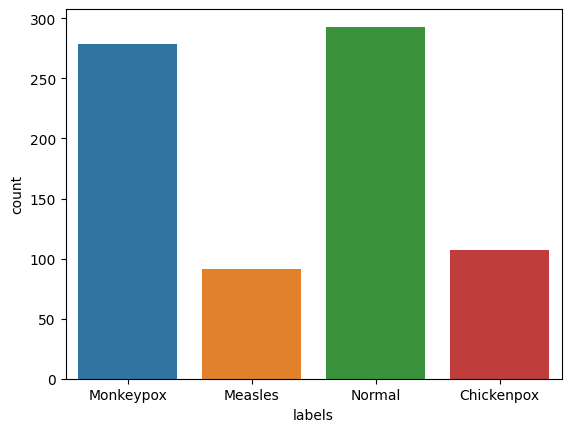

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x = 'labels', data=df)
plt.show()

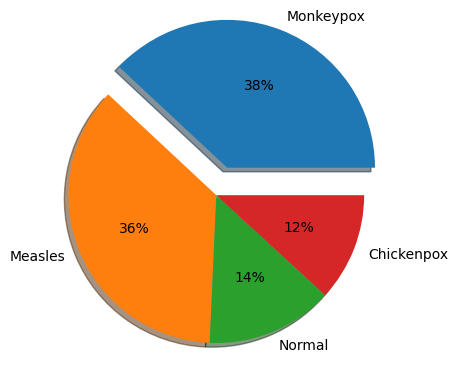

In [9]:
plt.pie(df['labels'].value_counts(),labels=['Monkeypox','Measles','Normal','Chickenpox'],autopct='%1.f%%',shadow=True,explode = (0.2,0,0,0))
plt.show()

Text(0.5, 1.0, 'Skin Disease')

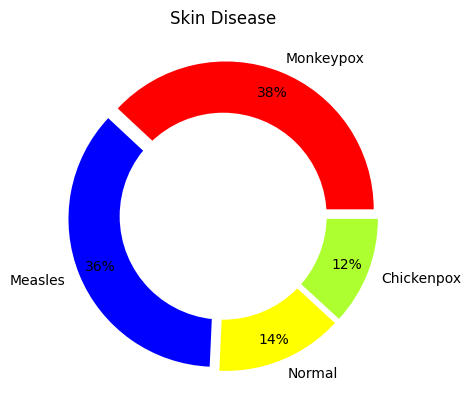

In [10]:
labels = ['Monkeypox','Measles','Normal','Chickenpox']
Labels = df['labels'].value_counts()
colors = ['#FF0000','#0000FF','#FFFF00','#ADFF2F','FFA500']
explode = (0.05,0.05,0.05,0.05)
plt.pie(Labels,labels=labels,colors=colors,autopct='%1.f%%',pctdistance=0.85,explode=explode)
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Skin Disease')

In [11]:
class_labels, class_counts = np.unique(df['labels'],return_counts=True)
total_samples = np.sum(class_counts)
weights= {
    class_label : total_samples / (class_counts[i] * len(class_labels))
    for i, class_label in enumerate(class_labels)
}
print(class_labels, class_counts, total_samples)
class_counts = df['labels'].value_counts()
balanced_data = []

for class_label in df['labels'].unique():
    subset = df[df['labels'] == class_label]
    num_images = max(293, len(subset))
    
    balanced_subset = subset.sample(n = num_images, random_state=42, replace=True)
    balanced_data.append(balanced_subset)
    
    balanced_df = pd.concat(balanced_data)
    balanced_df.reset_index(drop=True, inplace=True)
    print(balanced_df)

['Chickenpox' 'Measles' 'Monkeypox' 'Normal'] [107  91 279 293] 770
                                             file_path     labels
0    /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
1    /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
2    /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
3    /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
4    /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
..                                                 ...        ...
288  /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
289  /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
290  /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
291  /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox
292  /kaggle/input/monkeypoxskinimagedataset/Monkey...  Monkeypox

[293 rows x 2 columns]
                                             file_path     labels
0    /kaggle/input/monkeypoxskinimagedataset/Monke

In [12]:
balanced_df

,file_path,labels
0,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
1,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
2,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
3,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
4,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Monkeypox
...,...,...
1167,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
1168,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
1169,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox
1170,/kaggle/input/monkeypoxskinimagedataset/Monkey...,Chickenpox


In [13]:
from sklearn.model_selection import train_test_split
train_df, dummy_df = train_test_split(balanced_df,train_size=0.8,random_state=42)
val_df, test_df = train_test_split(dummy_df,train_size=0.5,random_state=42)

In [14]:
train_datagen = ImageDataGenerator(rescale=1.0/255, rotation_range=20,horizontal_flip=True,shear_range=0.2,zoom_range=0.2,height_shift_range=0.2,width_shift_range=0.2,fill_mode='nearest')
datagen = ImageDataGenerator(rescale=1.0/255)
train_ds = datagen.flow_from_dataframe(
    train_df,
    target_size=(224,224),
    batch_size = 32,
    color_mode = 'rgb',
    class_mode = 'categorical',
    labels = ['Monkeypox','Measles','Normal','Chickenpox'],
    x_col = 'file_path',
    y_col = 'labels',
    shuffle = False
)
test_ds = datagen.flow_from_dataframe(
    test_df,
    target_size = (224,224),
    batch_size = 32,
    color_mode = 'rgb',
    class_mode = 'categorical',
    x_col = 'file_path',
    y_col = 'labels',
    labels = ['Monkeypox','Measles','Normal','Chickenpox'],
    shuffle = False
)
val_ds = datagen.flow_from_dataframe(
    val_df,
    target_size = (224,224),
    batch_size = 32,
    class_mode = 'categorical',
    color_mode = 'rgb',
    x_col = 'file_path',
    y_col = 'labels',
    labels = ['Monkeypox','Measles','Normal','Chickenpox'],
    shuffle = False
)

Found 937 validated image filenames belonging to 4 classes.
Found 118 validated image filenames belonging to 4 classes.
Found 117 validated image filenames belonging to 4 classes.


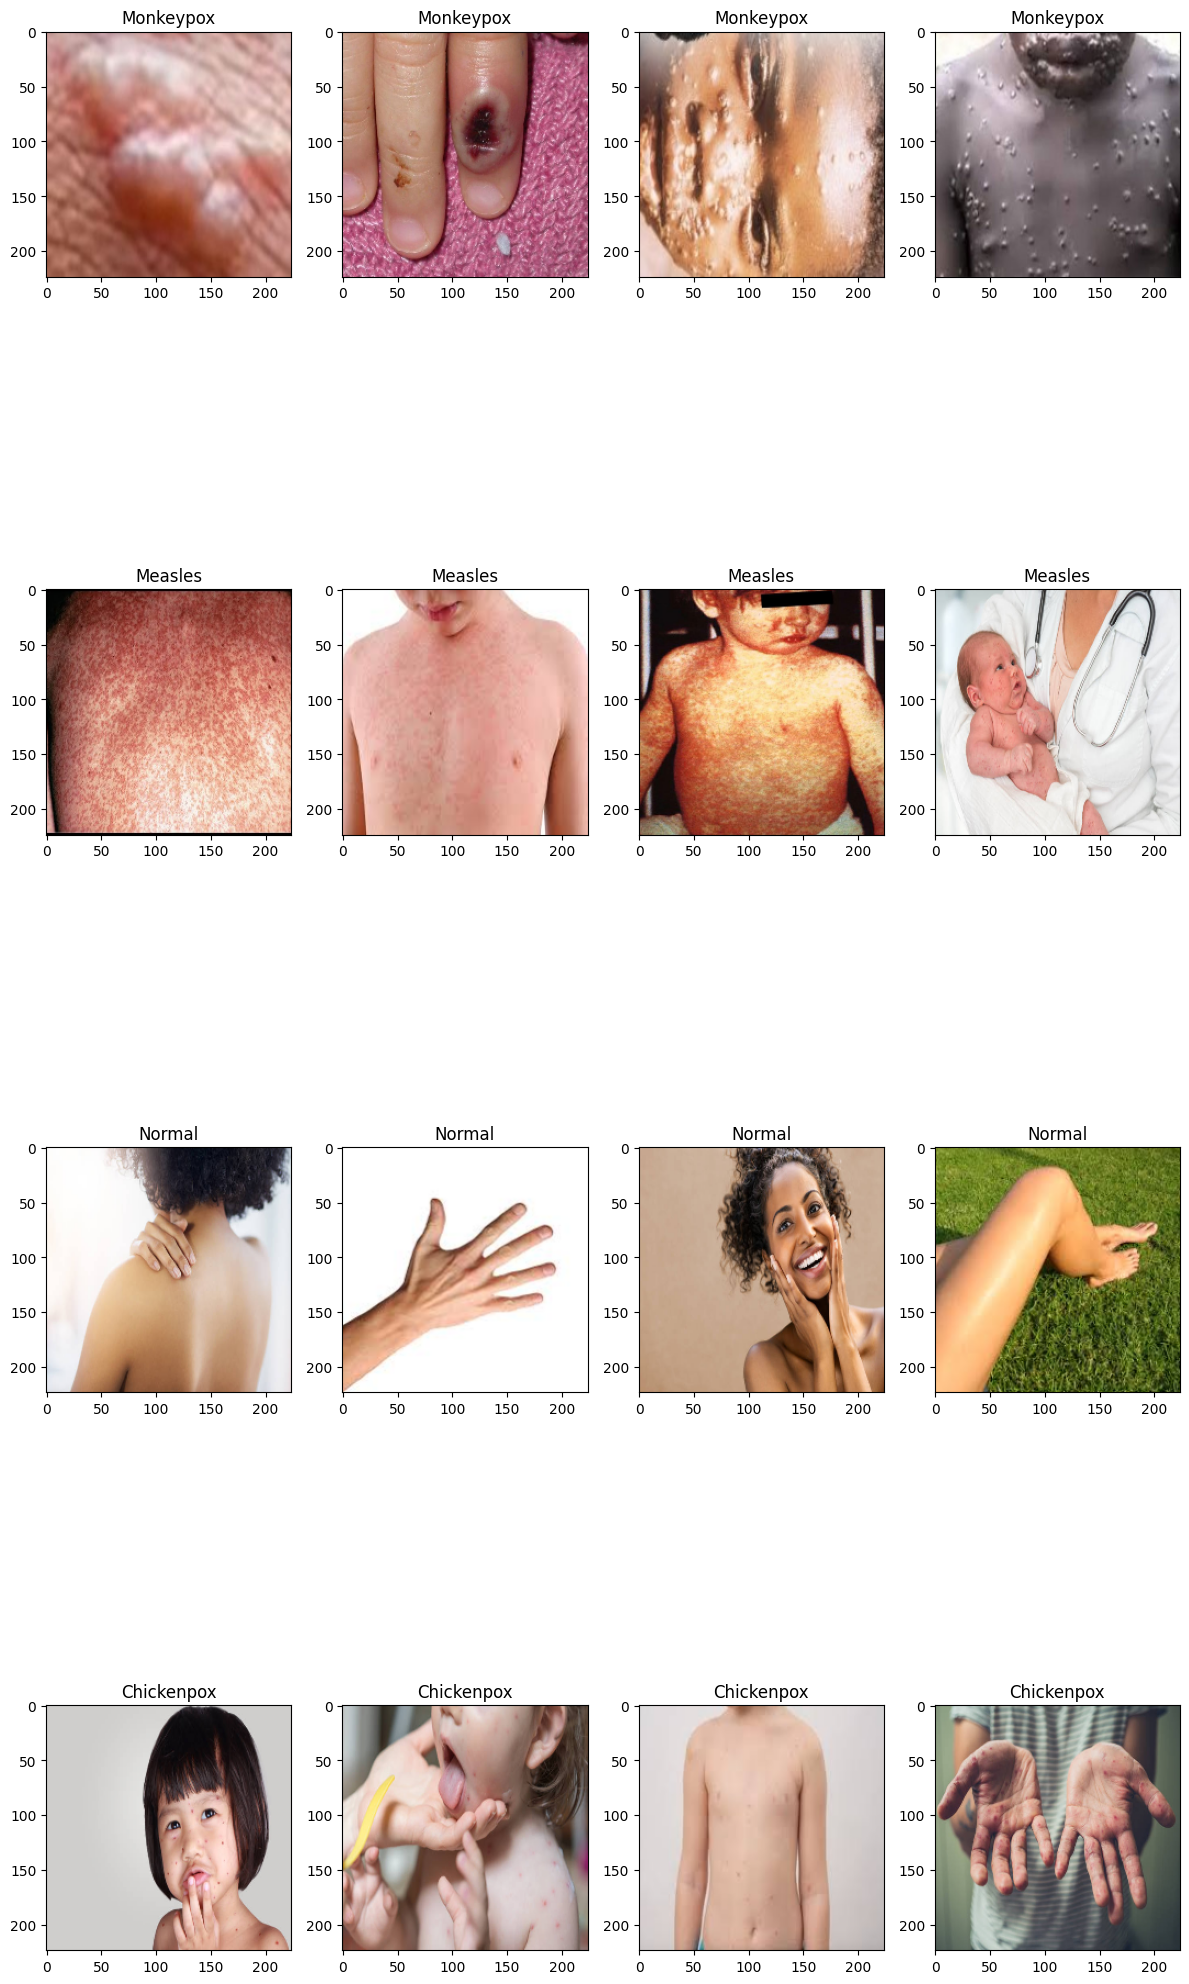

In [15]:
import PIL
from PIL import Image
num_image_per_class = 4
num_classes = len(classes)
plt.figure(figsize = (12, num_classes*6))
for i, class_name in enumerate(classes):
    class_folder = os.path.join(data, class_name)
    image = os.listdir(class_folder)
    
    for j in range(min(num_image_per_class, len(image))):
        
        img_path = os.path.join(class_folder, image[j])
        img = Image.open(img_path)
        
        plt.subplot(num_classes, num_image_per_class, i*num_image_per_class + j +1)
        plt.imshow(img)
        plt.asix=('off')
        plt.title(class_name)
plt.tight_layout()
plt.show()

In [16]:
base_model = VGG16(weights='imagenet',include_top=False,input_shape=(224,224,3))
for layer in base_model.layers:
    layer.trainable = False
x = base_model.output
x = Flatten()(x)
output = Dense(4, activation='softmax')(x)
monkeypox = Model(base_model.input, output)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [17]:
model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding='same',activation='relu',input_shape=(224,224,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='same'))

model.add(Conv2D(16,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='same'))

model.add(Flatten())
model.add(Dense(32,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(16,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(4,activation='softmax'))

/opt/conda/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
monkeypox.compile(optimizer='adam',loss = 'categorical_crossentropy', metrics=['accuracy'])

In [19]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [20]:
histroy = monkeypox.fit(train_ds, validation_data=val_ds,epochs=15)

Epoch 1/15


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1744900822.780914      68 service.cc:145] XLA service 0x78f804004430 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1744900822.780969      68 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0


 2/30 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.2734 - loss: 1.7889 

I0000 00:00:1744900831.689399      68 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 435ms/step - accuracy: 0.4581 - loss: 1.4608 - val_accuracy: 0.8291 - val_loss: 0.5036
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.8827 - loss: 0.3491 - val_accuracy: 0.8803 - val_loss: 0.3939
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.9495 - loss: 0.1850 - val_accuracy: 0.9231 - val_loss: 0.2719
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.9811 - loss: 0.0948 - val_accuracy: 0.9316 - val_loss: 0.2809
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.9883 - loss: 0.0821 - val_accuracy: 0.9402 - val_loss: 0.2001
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.9855 - loss: 0.0714 - val_accuracy: 0.9402 - val_loss: 0.1823
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.9932 - loss: 0.0584 - val_accuracy: 0.9573 - val_loss: 0.1518
Epoch 8/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.9968 - loss: 0.0412 - val_accuracy: 0.9487 - val_loss:

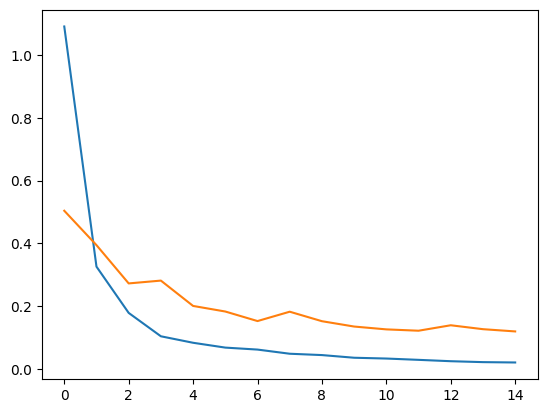

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.plot(histroy.history['loss'])
plt.plot(histroy.history['val_loss'])
plt.show()

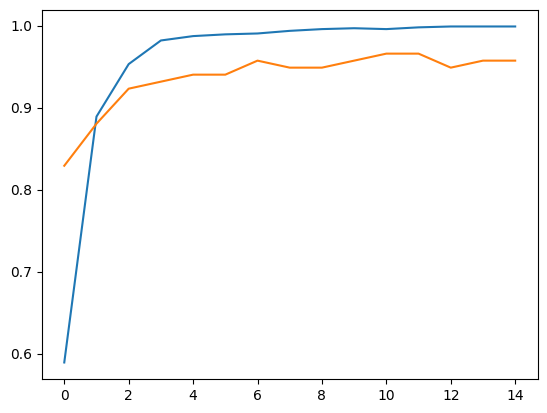

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.plot(histroy.history['accuracy'])
plt.plot(histroy.history['val_accuracy'])
plt.show()

In [23]:
train_score = monkeypox.evaluate(train_ds)
print('Train Loss:',train_score[0])
print('Train Accuracy:', train_score[1])

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.9998 - loss: 0.0172
Train Loss: 0.01677512377500534
Train Accuracy: 0.9989327788352966


In [24]:
test_score = monkeypox.evaluate(test_ds)
print('Test Loss:',test_score[0])
print('Test Accuracy:', test_score[1])

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9539 - loss: 0.1489
Test Loss: 0.13405968248844147
Test Accuracy: 0.9576271176338196


In [25]:
val_score = monkeypox.evaluate(val_ds)
print('Val Loss:',val_score[0])
print('Val Accuracy:', val_score[1])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9506 - loss: 0.1353
Val Loss: 0.1188015565276146
Val Accuracy: 0.9572649598121643


In [26]:
pred = monkeypox.predict(test_ds)
y_pred = np.argmax(pred, axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step


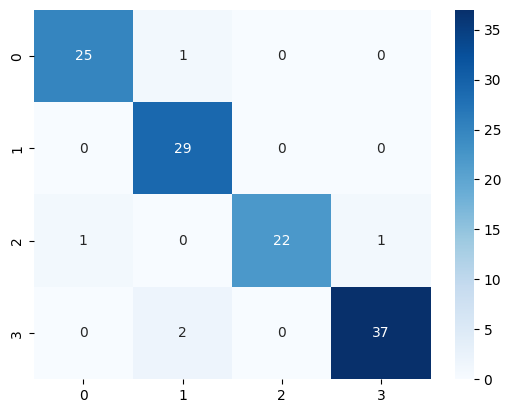

In [27]:
from sklearn.metrics import confusion_matrix, classification_report
confusion_matrix = confusion_matrix(test_ds.classes, y_pred)
sns.heatmap(confusion_matrix,annot=True,fmt='d',cmap='Blues')
plt.show()

In [28]:
confusion_matrix

array([[25,  1,  0,  0],
       [ 0, 29,  0,  0],
       [ 1,  0, 22,  1],
       [ 0,  2,  0, 37]])

In [29]:
print(classification_report(test_ds.classes, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96        26
           1       0.91      1.00      0.95        29
           2       1.00      0.92      0.96        24
           3       0.97      0.95      0.96        39

    accuracy                           0.96       118
   macro avg       0.96      0.96      0.96       118
weighted avg       0.96      0.96      0.96       118



In [30]:
from tensorflow.keras.models import load_model
monkeypox.save('monkeypox.h5',include_optimizer=True)

In [31]:
%cd kaggle/working
from IPython.display import FileLink
FileLink('monkeypox.h5')

[Errno 2] No such file or directory: 'kaggle/working'
/kaggle/working


/kaggle/working/monkeypox.h5